<a href="https://colab.research.google.com/github/katiezchang/CP101/blob/main/CP101_final_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CP101 Midterm Progress Report

In [1]:
import pandas as pd, geopandas as gpd
from shapely import wkt
from shapely.validation import make_valid
import pandas as pd, geopandas as gpd, folium
import folium
import zipfile
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import io, os, re, time
import numpy as np
import requests
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Data Cleaning

## Fault Lines 
https://data.bayareametro.gov/Land-People/Seismic-Hazard-Zone-Alquist-Priolo-HESS-/7fdj-fhcc/about_data

Finds where all the fault lines lie. Could be added with a dataset where we can see how far the effects of an earthquake reaches.

In [2]:
!pip -q install geopandas shapely folium mapclassify

df = pd.read_csv("data/Seismic_Hazard_Zone_(Alquist-Priolo)_(HESS)_20261026.csv")

df = df.replace(r"^\s*$", pd.NA, regex=True)

for c in ["map_releas", "zn_release"]:
    df[c] = pd.to_datetime(df[c])
for c in ["map_revise", "zn_revised"]:
    df[c] = df[c].map({"Y": True, "N": False})
for c in ["prev_map_r", "prev_zn_re"]:
    df[c] = df[c].str.replace(r"\s*;\s*", ";", regex=True)

df = df.drop(columns=["Shape__Area", "Shape__Length", "Shape_Area", "Shape_Length"])

df = df.rename(columns={
    "map_releas": "map_released", "map_revise": "map_revised", "prev_map_r": "prev_map_releases",
    "zn_release": "zone_released", "zn_revised": "zone_revised", "prev_zn_re": "prev_zone_releases",
    "geopdflink": "map_pdf_link", "reportlink": "report_link",
})

gdf = gpd.GeoDataFrame(df, geometry=df["geometry"].apply(wkt.loads), crs="EPSG:4326")
gdf["geometry"] = gdf.geometry.apply(make_valid)

gdf = gdf.to_crs("EPSG:3310")
gdf["area_m2"] = gdf.area

print(gdf.shape)                                    # expect (133, 13)
print("all valid:", gdf.is_valid.all())
print("duplicate shapes:", gdf.geometry.to_wkb().duplicated().sum())
print("total km²:", round(gdf["area_m2"].sum() / 1e6, 1))  # ~469
gdf.dtypes

gdf.to_file("data/ap_fault_zones_clean.gpkg", driver="GPKG")

(133, 13)
all valid: True
duplicate shapes: 0
total km²: 468.9


## Historic Earthquakes
https://www.usgs.gov/maps/earthquakes-and-faults-san-francisco-bay-area-1970-2003

In [3]:
target_file = "data/bayarea_earthquakes (1).csv"

print(f"Reading and cleaning: {target_file}")
df = pd.read_csv(target_file)
df.columns = df.columns.str.lower().str.strip()

lat_col = 'latitude (n)'
lon_col = 'longitude (w)'

# Clean coordinates
df = df.dropna(subset=[lat_col, lon_col])
df[lat_col] = pd.to_numeric(df[lat_col], errors='coerce')
df[lon_col] = pd.to_numeric(df[lon_col], errors='coerce')
df = df.dropna(subset=[lat_col, lon_col])

# Convert positive longitude (W) to negative degrees decimal for correct mapping
df[lon_col] = -df[lon_col].abs()

# Convert date to datetime
if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Convert to GeoDataFrame
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df[lon_col], df[lat_col]),
    crs="EPSG:4326"
)

    # Reproject to California Albers
gdf_projected = gdf.to_crs("EPSG:3310")
print(f"Successfully loaded and cleaned {len(gdf_projected)} earthquake records!")

# Save cleaned dataset
gdf_projected.to_file("data/sfba_earthquakes_clean.gpkg", driver="GPKG")
print("Saved cleaned dataset as 'sfba_earthquakes_clean.gpkg'")

Reading and cleaning: data/bayarea_earthquakes (1).csv
Successfully loaded and cleaned 22 earthquake records!
Saved cleaned dataset as 'sfba_earthquakes_clean.gpkg'


C:\Users\katie\AppData\Local\Temp\ipykernel_54500\3992400318.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['date'] = pd.to_datetime(df['date'], errors='coerce')


## HCD APR Data
https://www.huduser.gov/portal/datasets/cp.html#data_2006-2022

In [4]:
zip_path = "data/2018thru2022-050-csv (1).zip"

with zipfile.ZipFile(zip_path, "r") as z:
    print(z.namelist())

zip_path = "data/2018thru2022-050-csv (1).zip"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("050/Table1.csv") as f:
        income = pd.read_csv(f, encoding="latin1")
zip_path = "data/2018thru2022-050-csv (1).zip"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("050/Table1.csv") as f:
        Household = pd.read_csv(f, encoding="latin1")

income.head()
Household.select_dtypes(include="object").columns.tolist()
Household.isna().sum()[Household.isna().sum() > 0]
Household = Household.rename(columns={
    "source": "Year",
    "sumlevel": "Geography_Level",
    "geoid": "County_ID",
    "name": "County",
    "st": "State_Code",
    "cnty": "County_Code"
})

bay_area = [
    "Alameda County, California",
    "Contra Costa County, California",
    "Marin County, California",
    "Napa County, California",
    "San Francisco County, California",
    "San Mateo County, California",
    "Santa Clara County, California",
    "Solano County, California",
    "Sonoma County, California"
]

bay_household = Household[Household["County"].isin(bay_area)].copy()

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("050/Table8.csv") as f:
        table8 = pd.read_csv(f, encoding="latin1")

bay8 = table8[table8["name"].isin(bay_area)].copy()

bay8["Below 50%"] = bay8["T8_est3"] + bay8["T8_est16"] + bay8["T8_est69"] + bay8["T8_est82"]
bay8["50-80%"] = bay8["T8_est29"] + bay8["T8_est95"]
bay8["80-100%"] = bay8["T8_est42"] + bay8["T8_est108"]
bay8["Above 100%"] = bay8["T8_est55"] + bay8["T8_est121"]

income_cols = ["Below 50%", "50-80%", "80-100%", "Above 100%"]

county_income = bay8.set_index("name")[income_cols]
county_income.index = county_income.index.str.replace(" County, California", "", regex=False)
county_income = county_income.div(county_income.sum(axis=1), axis=0) * 100
check = bay8[["name", "T8_est1"]].copy()
check["Calculated_Total"] = bay8[income_cols].sum(axis=1)
check["Difference"] = check["Calculated_Total"] - check["T8_est1"]

['050/', '050/Table1.csv', '050/Table10.csv', '050/Table11.csv', '050/Table12.csv', '050/Table13.csv', '050/Table14A.csv', '050/Table14B.csv', '050/Table15A.csv', '050/Table15B.csv', '050/Table15C.csv', '050/Table16.csv', '050/Table17A.csv', '050/Table17B.csv', '050/Table18A.csv', '050/Table18B.csv', '050/Table18C.csv', '050/Table2.csv', '050/Table3.csv', '050/Table4.csv', '050/Table5.csv', '050/Table6.csv', '050/Table7.csv', '050/Table8.csv', '050/Table9.csv']


C:\Users\katie\AppData\Local\Temp\ipykernel_54500\602990754.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  Household.select_dtypes(include="object").columns.tolist()


In [5]:
# HUD CHAS ZIP file
zip_path = "data/2018thru2022-050-csv (1).zip"
with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("050/Table8.csv") as f:
        income_data = pd.read_csv(f, encoding="latin1")

# The nine Bay Area counties
bay_counties = [
    "Alameda", "Contra Costa", "Marin", "Napa", "San Francisco",
    "San Mateo", "Santa Clara", "Solano", "Sonoma"
]

income_data["county"] = income_data["name"].str.replace(
    " County, California", "", regex=False
)
bay_income = income_data[income_data["county"].isin(bay_counties)].copy()
bay_income["Below 50%"] = (
    bay_income["T8_est3"] + bay_income["T8_est16"]
    + bay_income["T8_est69"] + bay_income["T8_est82"]
)
bay_income["50–80%"] = (
    bay_income["T8_est29"] + bay_income["T8_est95"]
)

# Percentage of households below 80% of HAMFI
bay_income["Percent below 80%"] = (
    (bay_income["Below 50%"] + bay_income["50–80%"])
    / bay_income["T8_est1"] * 100
)

county_url = (
    "https://www2.census.gov/geo/tiger/GENZ2023/shp/"
    "cb_2023_us_county_500k.zip"
)
counties = gpd.read_file(county_url).to_crs("EPSG:3310")

bay_map = counties[
    (counties["STATEFP"] == "06") & (counties["NAME"].isin(bay_counties))
].copy()

bay_map = bay_map.merge(
    bay_income[["county", "Percent below 80%"]],
    left_on="NAME",
    right_on="county",
    how="left"
)


C:\Users\katie\AppData\Local\Temp\ipykernel_54500\297256702.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  income_data["county"] = income_data["name"].str.replace(


## CTAC Data for State Low Income tax Credits
https://www.treasurer.ca.gov/ctcac/projects

In [6]:
filename = "data/List of Projects_1.xlsx"

workbook = pd.ExcelFile(filename)
print("Sheets:", workbook.sheet_names)

ctcac = pd.read_excel(filename, sheet_name=0)
ctcac = pd.read_excel(filename, sheet_name="California Mapped Projects")

# The 9 Bay Area counties
bay_counties = [
    "Alameda", "Contra Costa", "Marin", "Napa", "San Francisco",
    "San Mateo", "Santa Clara", "Solano", "Sonoma"
]

projects = ctcac.copy()

projects["Project County"] = projects["Project County"].fillna("").astype(str).str.strip()
projects["Project City"] = projects["Project City"].fillna("").astype(str).str.strip()

# Keep projects in the 9 counties
bay_projects = projects[
    projects["Project County"].str.casefold().isin(
        [county.casefold() for county in bay_counties]
    )
].copy()

bay_projects["Low Income Units"] = pd.to_numeric(
    bay_projects["Low Income Units"], errors="coerce"
)

print("Bay Area project rows:", len(bay_projects))
print("Missing unit counts:", bay_projects["Low Income Units"].isna().sum())


city_units = (
    bay_projects.groupby(["Project County", "Project City"])["Low Income Units"]
    .sum(min_count=1)
    .reset_index()
    .sort_values("Low Income Units", ascending=False)
)
# Matching  CTCAC abriv to the Census place name
city_units["Project City"] = city_units["Project City"].replace({
    "Pt. Reyes Station": "Point Reyes Station"
})

Sheets: ['Instructions', 'California Mapped Projects', 'Alameda', 'Alpine', 'Amador', 'Butte', 'Calaveras', 'Colusa', 'Contra Costa', 'Del Norte', 'El Dorado', 'Fresno', 'Glenn', 'Humboldt', 'Imperial', 'Inyo', 'Kern', 'Kings', 'Lake', 'Lassen', 'Los Angeles', 'Madera', 'Marin', 'Mariposa', 'Mendocino', 'Merced', 'Modoc', 'Mono', 'Monterey', 'Napa', 'Nevada', 'Orange', 'Placer', 'Plumas', 'Riverside', 'Sacramento', 'San Benito', 'San Bernardino', 'San Diego', 'San Francisco', 'San Joaquin', 'San Luis Obispo', 'San Mateo', 'Santa Barbara', 'Santa Clara', 'Santa Cruz', 'Shasta', 'Sierra', 'Siskiyou', 'Solano', 'Sonoma', 'Stanislaus', 'Sutter', 'Tehama', 'Tulare', 'Tuolumne', 'Ventura', 'Yolo', 'Yuba']
Bay Area project rows: 1510
Missing unit counts: 72


### Census City Boundaries & Mapped Projects

In [7]:
# Download Census city boundaries and county boundaries for California
cities_url = (
    "https://www2.census.gov/geo/tiger/GENZ2023/shp/"
    "cb_2023_06_place_500k.zip"
)
counties_url = (
    "https://www2.census.gov/geo/tiger/GENZ2023/shp/"
    "cb_2023_us_county_500k.zip"
)

cities = gpd.read_file(cities_url).to_crs("EPSG:3310")
counties = gpd.read_file(counties_url).to_crs(cities.crs)

# Keep the nine Bay Area counties
bay_boundary = counties[counties["NAME"].isin(bay_counties)]

# Keep city boundaries that intersect the Bay Area
bay_cities = gpd.clip(cities, bay_boundary)


totals = city_units.copy()
totals["city_key"] = totals["Project City"].str.strip().str.casefold()
totals = totals.groupby("city_key")["Low Income Units"].sum(min_count=1)

bay_cities["city_key"] = bay_cities["NAME"].str.strip().str.casefold()
bay_cities = bay_cities.merge(
    totals, left_on="city_key", right_index=True, how="left"
)


In [8]:
print("UNMATCHED PROJECT CITY NAMES:")
unmatched = sorted(set(totals.index) - set(bay_cities["city_key"]))
print("Project city names without a matching boundary:", unmatched)
print(unmatched)

print("\nPROJECTS WITH MISSING UNIT COUNTS:")
missing = bay_projects[bay_projects["Low Income Units"].isna()]
display(missing[[
    "Application Number",
    "Project Name",
    "Project City",
    "Project County",
    "Low Income Units"
]])
unmatched_projects = bay_projects[
    bay_projects["Project City"].str.strip().str.casefold().isin(unmatched)
]

display(unmatched_projects[[
    "Application Number",
    "Project Name",
    "Project Address",
    "Project City",
    "Project County",
    "Low Income Units"
]])

print("Known units in unmatched rows:",
      unmatched_projects["Low Income Units"].sum())
display(
    bay_cities[
        bay_cities["NAME"].str.contains("Reyes", case=False, na=False)
    ][["NAME"]]
)
# ---- File paths ----
CTCAC_XLSX    = "data/List of Projects_1.xlsx"
CTCAC_SHEET   = "California Mapped Projects"
EQ_CSV        = "data/bayarea_earthquakes (1).csv"
GEOCODE_CACHE = "data/ctcac_geocoded.csv"
OUT_DIR       = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# ---- Analysis settings ----
PROJ_CRS       = "EPSG:3310"       # California Albers, units = meters
BUFFERS_KM     = [5, 10, 25]       # sensitivity radii around each epicenter
MAIN_BUFFER_KM = 10                # radius used for the map and county table

BAY_COUNTIES = {
    "Alameda": "001", "Contra Costa": "013", "Marin": "041", "Napa": "055",
    "San Francisco": "075", "San Mateo": "081", "Santa Clara": "085",
    "Solano": "095", "Sonoma": "097",
}
BAY_BBOX = dict(lon_min=-123.6, lon_max=-121.1, lat_min=36.8, lat_max=39.0)

cleaning_log = []   # (step, rows affected, why)
def log(step, n, why):
    cleaning_log.append((step, n, why))
    print(f"{step}: {n:,}  |  {why}")

UNMATCHED PROJECT CITY NAMES:
Project city names without a matching boundary: ['marin county']
['marin county']

PROJECTS WITH MISSING UNIT COUNTS:


,Application Number,Project Name,Project City,Project County,Low Income Units
777,CA-1999-886,Papago Court / Apple Valley Apartments (Site B),Santa Rosa,Sonoma,NaN
899,CA-2000-849,Paulin Creek Apartments (Site B),Santa Rosa,Sonoma,NaN
1465,CA-2004-113,San Jose Art Ark Housing (Site B),San Jose,Santa Clara,NaN
2115,CA-2007-858,Windsor Park Apartments (Site B),Concord,Contra Costa,NaN
2253,CA-2008-847,Rohlffs Concordia Manor/Rohlffs Manor III (Sit...,Napa,Napa,NaN
...,...,...,...,...,...
6031,CA-2025-753,Apple Valley Scattered Sites (Site 2),Santa Rosa,Sonoma,NaN
6062,CA-2025-790,City Towers (Site 2),Oakland,Alameda,NaN
6213,CA-2026-571,Chestnut Linden Resyndication (Site 2: Linden),Oakland,Alameda,NaN
6215,CA-2026-572,Berkeley Senior Recap (Site 2: Margaret Breland),Berkeley,Alameda,NaN


,Application Number,Project Name,Project Address,Project City,Project County,Low Income Units
6052,CA-2025-784,Oak Hill Eden,"Sir Frances Drake Blvd, Marin County, CA 94964",Marin County,Marin,113.0


Known units in unmatched rows: 113.0


,NAME
1546,Point Reyes Station


# Combined Datasets
SFBA Earthquakes Data and Housing

In [9]:
raw = pd.read_excel(CTCAC_XLSX, sheet_name=CTCAC_SHEET)
log("Statewide CTCAC rows loaded", len(raw), "starting point")

raw["county"] = raw["Project County"].astype(str).str.strip().str.title()
housing = raw[raw["county"].isin(BAY_COUNTIES)].copy()
log("Rows outside the 9 Bay Area counties removed", len(raw) - len(housing),
    "project area is the nine-county Bay Area")
log("Bay Area project rows kept", len(housing), "matches the 1,510 in the Data section")

for c in ["Total Units", "Low Income Units"]:
    housing[c] = pd.to_numeric(housing[c], errors="coerce")
n_missing = housing["Low Income Units"].isna().sum()
n_site = (housing["Low Income Units"].isna()
          & housing["Project Name"].str.contains(r"\bSites?\b", case=False, regex=True)).sum()
log("Rows with missing Low Income Units (kept as NaN)", n_missing,
    f"{n_site} of them are extra-site rows ('Site B', 'Site C') of multi-site projects whose units appear to be "
    "reported once on the 'Site A' row, so leaving NaN avoids double counting")

housing["row_id"] = housing.index
housing["year_placed"] = pd.to_datetime(
    housing["Placed in Service (PIS) Date "], errors="coerce").dt.year

cols = ["row_id", "input", "match", "match_type", "matched_addr", "coords", "tiger_id", "side"]
res = pd.read_csv("data/GeocodeResults.csv", header=None, names=cols, dtype=str)
res["row_id"] = res["row_id"].astype(int)
ok = res["match"] == "Match"
res["lon"] = np.nan; res["lat"] = np.nan
res.loc[ok, ["lon", "lat"]] = res.loc[ok, "coords"].str.split(",", expand=True).astype(float).values
res[["row_id", "lon", "lat", "match_type"]].to_csv(GEOCODE_CACHE, index=False)

def clean_street(addr, city):
    s = str(addr)
    s = re.sub(r",?\s*CA\s*\d{5}.*$", "", s, flags=re.I)
    s = re.sub(r"\s*(#|apt\.?|unit|suite|ste\.?)\s*\S+", "", s, flags=re.I)
    s = s.split(",")[0].strip()
    city = str(city).strip()
    if city and s.lower().endswith(city.lower()):
        s = s[: -len(city)].strip()
    return s

def census_batch_geocode(df, chunk=1000, benchmark="Public_AR_Current"):
    url = "https://geocoding.geo.census.gov/geocoder/locations/addressbatch"
    cols = ["row_id", "input", "match", "match_type", "matched_addr", "coords", "tiger_id", "side"]
    parts = []
    for i in range(0, len(df), chunk):
        sub = df.iloc[i:i + chunk]
        buf = io.StringIO()
        pd.DataFrame({
            "id": sub["row_id"],
            "street": [clean_street(a, c) for a, c in zip(sub["Project Address"], sub["Project City"])],
            "city": sub["Project City"].astype(str).str.strip(),
            "state": "CA",
            "zip": sub["Project Zip Code"].astype(str).str.extract(r"(\d{5})")[0],
        }).to_csv(buf, index=False, header=False)
        for attempt in range(3):
            try:
                r = requests.post(url, files={"addressFile": ("a.csv", buf.getvalue())},
                                  data={"benchmark": benchmark}, timeout=300)
                r.raise_for_status()
                break
            except Exception as e:
                print(f"  chunk {i}: attempt {attempt + 1} failed ({e})")
                time.sleep(5)
        else:
            raise RuntimeError("Census geocoder not reachable; try again or run from Colab with internet on.")
        out = pd.read_csv(io.StringIO(r.text), header=None, names=cols, dtype=str)
        parts.append(out)
        print(f"  geocoded {min(i + chunk, len(df)):,} / {len(df):,}")
        time.sleep(1)
    res = pd.concat(parts, ignore_index=True)
    res["row_id"] = res["row_id"].astype(int)
    ok = res["match"] == "Match"
    res["lon"] = np.nan; res["lat"] = np.nan
    res.loc[ok, ["lon", "lat"]] = res.loc[ok, "coords"].str.split(",", expand=True).astype(float).values
    return res[["row_id", "lon", "lat", "match_type"]]

geo = pd.read_csv(GEOCODE_CACHE) if os.path.exists(GEOCODE_CACHE) else None
if geo is None or not set(housing["row_id"]).issubset(set(geo["row_id"])):
    print("Geocoding with the Census batch geocoder...")
    geo = census_batch_geocode(housing)
    geo.to_csv(GEOCODE_CACHE, index=False)
else:
    print(f"Using cached geocodes from {GEOCODE_CACHE}")

housing = housing.merge(geo, on="row_id", how="left")
housing["loc_method"] = np.where(housing["lon"].notna(), "census_geocoder", None)
log("Projects placed by Census geocoder", housing["lon"].notna().sum(), "street-address match")

def parse_tract(x):
    s = str(x).strip()
    if not re.fullmatch(r"\d{1,4}(\.\d{1,2})?", s):
        return None
    return f"{round(float(s) * 100):06d}"

housing["tract6"] = housing["Census Tract"].map(parse_tract)
housing["tract_geoid"] = np.where(
    housing["tract6"].notna(),
    "06" + housing["county"].map(BAY_COUNTIES).fillna("") + housing["tract6"].fillna(""), None)

missing_loc = housing["lon"].isna()
if missing_loc.any():
    try:
        tracts = gpd.read_file("https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_06_tract_500k.zip")
        cent = tracts.to_crs(PROJ_CRS).assign(geometry=lambda d: d.geometry.centroid).to_crs("EPSG:4326")
        cent = cent.set_index("GEOID").geometry
        fb = housing.loc[missing_loc, "tract_geoid"].map(
            lambda g: cent.get(g) if isinstance(g, str) else None)
        ok = fb.notna()
        housing.loc[fb[ok].index, "lon"] = fb[ok].map(lambda p: p.x)
        housing.loc[fb[ok].index, "lat"] = fb[ok].map(lambda p: p.y)
        housing.loc[fb[ok].index, "loc_method"] = "tract_centroid"
        log("Projects placed by tract-centroid fallback", int(ok.sum()),
            "geocoder found no match; tract centroid is a coarser location (~1-3 km)")
    except Exception as e:
        print("Tract fallback skipped (could not download census tracts):", e)

inside = (housing["lon"].between(BAY_BBOX["lon_min"], BAY_BBOX["lon_max"])
          & housing["lat"].between(BAY_BBOX["lat_min"], BAY_BBOX["lat_max"]))
bad = housing["lon"].notna() & ~inside
log("Geocodes outside the Bay Area box (set to unlocated)", int(bad.sum()), "bad matches would distort distances")
housing.loc[bad, ["lon", "lat", "loc_method"]] = np.nan

n_unlocated = housing["lon"].isna().sum()
log("Projects with no usable location (excluded from join)", int(n_unlocated),
    f"{n_unlocated / len(housing):.1%} of Bay Area rows")

located = housing.dropna(subset=["lon", "lat"]).copy()
gdf_housing = gpd.GeoDataFrame(
    located, geometry=gpd.points_from_xy(located["lon"], located["lat"]), crs="EPSG:4326"
).to_crs(PROJ_CRS)
print("\nLocation method:\n", gdf_housing["loc_method"].value_counts().to_string())
print("Projects in the join:", len(gdf_housing))

Statewide CTCAC rows loaded: 6,283  |  starting point
Rows outside the 9 Bay Area counties removed: 4,773  |  project area is the nine-county Bay Area
Bay Area project rows kept: 1,510  |  matches the 1,510 in the Data section
Rows with missing Low Income Units (kept as NaN): 72  |  71 of them are extra-site rows ('Site B', 'Site C') of multi-site projects whose units appear to be reported once on the 'Site A' row, so leaving NaN avoids double counting
Using cached geocodes from data/ctcac_geocoded.csv
Projects placed by Census geocoder: 1,381  |  street-address match
Projects placed by tract-centroid fallback: 91  |  geocoder found no match; tract centroid is a coarser location (~1-3 km)
Geocodes outside the Bay Area box (set to unlocated): 0  |  bad matches would distort distances
Projects with no usable location (excluded from join): 38  |  2.5% of Bay Area rows

Location method:
 loc_method
census_geocoder    1381
tract_centroid       91
Projects in the join: 1472


In [10]:
EQ_GPKG = "data/sfba_earthquakes_clean.gpkg"

gdf_eq = gpd.read_file(EQ_GPKG).to_crs(PROJ_CRS)
gdf_eq = gdf_eq.rename(columns={
    "earthquake no.": "eq_no",
    "magnitude (richter scale)": "mag",
    "depth (km)": "depth_km",
})
gdf_eq["eq_no"] = gdf_eq["eq_no"].astype(int)
gdf_eq["year"] = pd.to_datetime(gdf_eq["date"], errors="coerce").dt.year
log("Earthquakes loaded from cleaned file", len(gdf_eq), f"{EQ_GPKG}")
print(f"{len(gdf_eq)} earthquakes, M{gdf_eq['mag'].min():.1f}-M{gdf_eq['mag'].max():.1f}, "
      f"{gdf_eq['year'].min()}-{gdf_eq['year'].max()}")

# ---- Join 1: nearest epicenter ----
eq_cols = gdf_eq[["eq_no", "year", "mag", "geometry"]].rename(
    columns={"eq_no": "nearest_eq_no", "year": "nearest_eq_year", "mag": "nearest_eq_mag"})
nearest = gpd.sjoin_nearest(gdf_housing, eq_cols, how="left", distance_col="dist_m")
nearest = nearest.sort_values("dist_m")
nearest = nearest[~nearest.index.duplicated(keep="first")]
nearest["dist_km"] = nearest["dist_m"] / 1000
assert len(nearest) == len(gdf_housing), "nearest join changed the number of projects"

# ---- Join 2: epicenter buffers ----
buf_main = gdf_eq[["eq_no", "mag", "geometry"]].copy()
buf_main["geometry"] = buf_main.geometry.buffer(MAIN_BUFFER_KM * 1000)
inbuf = gpd.sjoin(gdf_housing[["row_id", "geometry"]], buf_main, how="inner", predicate="intersects")
agg = inbuf.groupby(inbuf.index).agg(n_quakes_in_buffer=("eq_no", "nunique"),
                                      max_mag_in_buffer=("mag", "max"))
result = nearest.join(agg)
result["n_quakes_in_buffer"] = result["n_quakes_in_buffer"].fillna(0).astype(int)

for r in BUFFERS_KM:
    result[f"within_{r}km"] = result["dist_km"] <= r

agree = ((result["n_quakes_in_buffer"] > 0) == result[f"within_{MAIN_BUFFER_KM}km"]).mean()
print(f"Buffer join vs distance rule agree on {agree:.2%} of projects at {MAIN_BUFFER_KM} km")
print(f"Rows in raw buffer join: {len(inbuf)}  ->  unique projects: {inbuf.index.nunique()} "
      "(difference = projects inside more than one buffer)")

def exposure_summary(res, radii):
    rows = []
    tot_units = res["Low Income Units"].sum()
    for r in radii:
        m = res[f"within_{r}km"]
        rows.append({
            "radius_km": r,
            "projects_within": int(m.sum()),
            "pct_projects": 100 * m.mean(),
            "low_income_units_within": res.loc[m, "Low Income Units"].sum(),
            "pct_low_income_units": 100 * res.loc[m, "Low Income Units"].sum() / tot_units,
        })
    return pd.DataFrame(rows).round(1)

summary = exposure_summary(result, BUFFERS_KM)
print(f"Located projects: {len(result):,} | total low-income units: {result['Low Income Units'].sum():,.0f}")
display(summary)

print(f"\nBy county, within {MAIN_BUFFER_KM} km of an epicenter:")
by_county = (result.groupby("county")
             .agg(projects=("row_id", "size"),
                  within=(f"within_{MAIN_BUFFER_KM}km", "sum"),
                  low_income_units=("Low Income Units", "sum"),
                  units_within=("Low Income Units", lambda s: s[result.loc[s.index, f"within_{MAIN_BUFFER_KM}km"]].sum()))
             .assign(pct_projects=lambda d: (100 * d["within"] / d["projects"]).round(1))
             .sort_values("within", ascending=False))
display(by_county)

print("\nDistance from each project to its nearest epicenter (km):")
display(result["dist_km"].describe().round(1).to_frame().T)

Earthquakes loaded from cleaned file: 22  |  data/sfba_earthquakes_clean.gpkg
22 earthquakes, M5.0-M7.0, 1974-2000
Buffer join vs distance rule agree on 100.00% of projects at 10 km
Rows in raw buffer join: 40  ->  unique projects: 38 (difference = projects inside more than one buffer)
Located projects: 1,472 | total low-income units: 133,122


,radius_km,projects_within,pct_projects,low_income_units_within,pct_low_income_units
0,5,0,0.0,0.0,0.0
1,10,38,2.6,3478.0,2.6
2,25,490,33.3,50292.0,37.8



By county, within 10 km of an epicenter:


,projects,within,low_income_units,units_within,pct_projects
county,,,,,
Santa Clara,349,25,37394.0,2785.0,7.2
Alameda,332,7,26754.0,367.0,2.1
Sonoma,137,5,9364.0,302.0,3.6
Napa,32,1,2350.0,24.0,3.1
Contra Costa,162,0,16190.0,0.0,0.0
San Francisco,263,0,26227.0,0.0,0.0
Marin,37,0,2642.0,0.0,0.0
San Mateo,89,0,6329.0,0.0,0.0
Solano,71,0,5872.0,0.0,0.0



Distance from each project to its nearest epicenter (km):


,count,mean,std,min,25%,50%,75%,max
dist_km,1472.0,34.5,16.4,5.4,18.8,34.4,48.2,104.5


In [11]:
faults = gpd.read_file("data/ap_fault_zones_clean.gpkg").to_crs(PROJ_CRS)
ap_union = faults[["geometry"]].dissolve()          # merge overlapping zones so area isn't double counted
ap = gpd.sjoin_nearest(result[["row_id","geometry"]], faults[["zone_name","geometry"]], distance_col="ap_m")
ap = ap[~ap.index.duplicated()]
result["dist_ap_km"] = ap["ap_m"] / 1000
result["near_ap"] = result["dist_ap_km"] <= 1     # inside or within 1 km of an AP zone

# Maps

## Fault Zones

In [12]:
gdf = gpd.read_file("data/ap_fault_zones_clean.gpkg")

m_gdf = gdf.copy()
m_gdf["area_km2"] = (m_gdf["area_m2"] / 1e6).round(2)
m_gdf["released"] = pd.to_datetime(m_gdf["zone_released"]).dt.strftime("%b %Y")
m_gdf["revised"] = m_gdf["zone_revised"].map({True: "Yes", False: "No"})
m_gdf["map_pdf"] = '<a href="' + m_gdf["map_pdf_link"] + '" target="_blank">Open official map</a>'
m_gdf = m_gdf[["zone_name", "quad_name", "released", "revised", "area_km2", "map_pdf", "geometry"]]

m = m_gdf.explore(
    column="zone_name", cmap="tab20", legend=True,
    tooltip=["zone_name", "quad_name"],
    tooltip_kwds={"aliases": ["Fault zone", "Quadrangle"]},
    popup=True,
    popup_kwds={"aliases": ["Fault zone", "Quadrangle", "Zone released",
                            "Revised?", "Area (km²)", "Map"]},
    style_kwds={"weight": 1, "fillOpacity": 0.6},
    tiles="Esri.WorldGrayCanvas", name="Fault zones",
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri", name="Street map",
).add_to(m)

folium.LayerControl().add_to(m)

m

## Historic Earthquakes

In [13]:
# Load cleaned earthquake dataset
eq_gdf = gpd.read_file("data/sfba_earthquakes_clean.gpkg")
eq_map = eq_gdf.to_crs("EPSG:4326")

# Prepare columns for the explore map display
eq_map["event_date"] = pd.to_datetime(eq_map["date"]).dt.strftime("%b %d, %Y")
eq_map["magnitude"] = eq_map["magnitude (richter scale)"]
eq_map["depth_km"] = eq_map["depth (km)"]
eq_map["eq_number"] = eq_map["earthquake no."].astype(int)

# Calculate custom radii representing relative magnitudes
eq_map["radius"] = (eq_map["magnitude"] ** 2.5) * 0.15

# Keep only columns of interest
eq_explore = eq_map[["eq_number", "event_date", "magnitude", "depth_km", "radius", "geometry"]]

# Generate interactive explore map centered around San Francisco Bay Area
m = eq_explore.explore(
    column="magnitude",
    cmap="OrRd",
    legend=True,
    tooltip=["eq_number", "magnitude"],
    tooltip_kwds={"aliases": ["Earthquake #", "Magnitude (Richter)"]},
    popup=True,
    popup_kwds={"aliases": ["Earthquake #", "Date", "Magnitude", "Depth (km)", "Radius Marker Size"]},
    style_kwds={
        "style_function": lambda x: {
            "radius": x["properties"]["radius"],
            "fillOpacity": 0.7,
            "weight": 1.5,
            "color": "crimson"
        }
    },
    tiles="Esri.WorldGrayCanvas",
    name="Earthquakes"
)

# Overlay fault zones if the dataset is present
faults_file = "ap_fault_zones_clean.gpkg"
if os.path.exists(faults_file):
    faults_gdf = gpd.read_file(faults_file)
    faults_map = faults_gdf.to_crs("EPSG:4326")

    # Prepare fault data structure for map rendering
    m_faults = faults_map.copy()
    m_faults["area_km2"] = (m_faults["area_m2"] / 1e6).round(2)
    m_faults["released"] = pd.to_datetime(m_faults["zone_released"]).dt.strftime("%b %Y")
    m_faults["revised"] = m_faults["zone_revised"].map({True: "Yes", False: "No"})
    m_faults["map_pdf"] = '<a href="' + m_faults["map_pdf_link"] + '" target="_blank">Open official map</a>'
    m_faults = m_faults[["zone_name", "quad_name", "released", "revised", "area_km2", "map_pdf", "geometry"]]

    # Plot faults onto the existing map object 'm'
    m_faults.explore(
        m=m,
        column="zone_name",
        cmap="tab20",
        legend=True,
        tooltip=["zone_name", "quad_name"],
        tooltip_kwds={"aliases": ["Fault zone", "Quadrangle"]},
        popup=True,
        popup_kwds={"aliases": ["Fault zone", "Quadrangle", "Zone released", "Revised?", "Area (km²)", "Map"]},
        style_kwds={"weight": 1.5, "fillOpacity": 0.4},
        name="Fault zones"
    )
else:
    ...

# Add the secondary World Street Map background
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri",
    name="Street map",
).add_to(m)

# Add Layer Control to let user switch layers
folium.LayerControl().add_to(m)
m

## Household Income Distribution

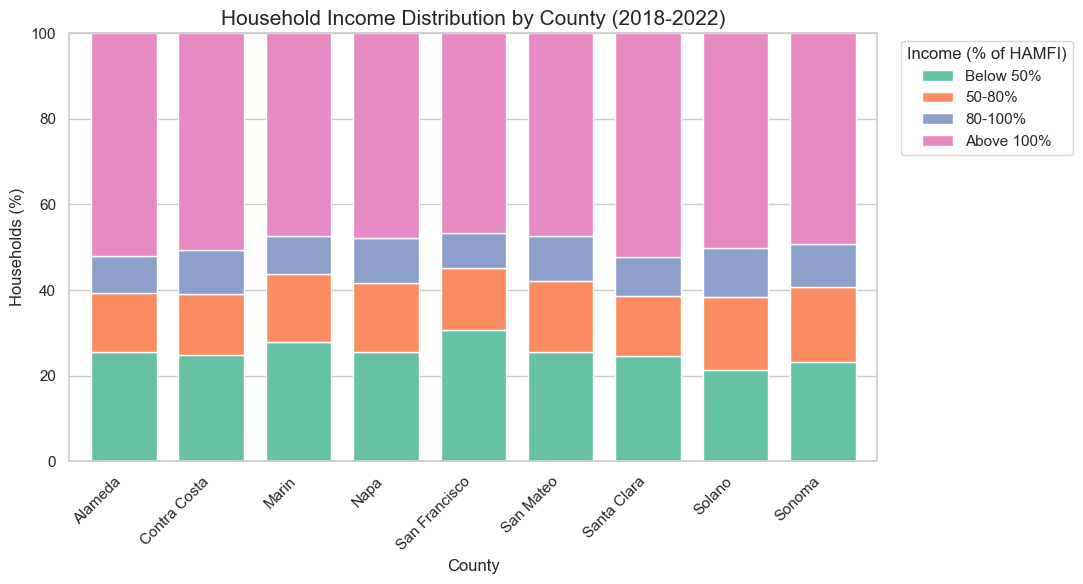

In [14]:
sns.set_theme(style="whitegrid")

ax = county_income.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    color=sns.color_palette("Set2", 4),
    edgecolor="white",
    width=0.75
)

plt.title("Household Income Distribution by County (2018-2022)", fontsize=15)
plt.xlabel("County")
plt.ylabel("Households (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)
plt.legend(title="Income (% of HAMFI)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


Describes percentage of households within different income brackets per county in Bay Area, denoted by different colors as specified in the legend.

## Households below HAMFI

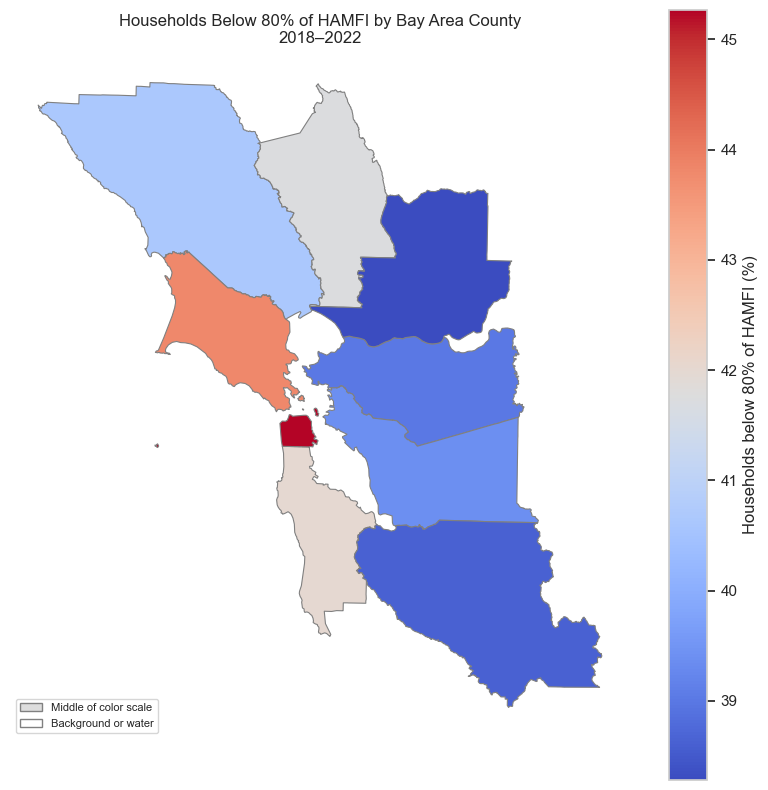

,NAME,Percent below 80%
0,Alameda,39.380697
1,Contra Costa,39.016241
2,Marin,43.804840
3,Napa,41.731004
4,San Francisco,45.266600
5,San Mateo,42.005107
6,Santa Clara,38.613055
7,Solano,38.281124
8,Sonoma,40.634310


In [15]:
# Draw the map
fig, ax = plt.subplots(figsize=(10, 10))

bay_map.plot(
    column="Percent below 80%",
    cmap="coolwarm",
    edgecolor="gray",
    linewidth=0.8,
    legend=True,
    legend_kwds={"label": "Households below 80% of HAMFI (%)"},
    missing_kwds={"color": "lightgray", "label": "Missing data"},
    ax=ax,
)

ax.set_title("Households Below 80% of HAMFI by Bay Area County\n2018–2022")
ax.set_axis_off()

from matplotlib.patches import Patch

legend_items = [
    Patch(facecolor="#dddddd", edgecolor="gray",
          label="Middle of color scale"),
    Patch(facecolor="white", edgecolor="gray",
          label="Background or water")
]

ax.legend(handles=legend_items, loc="lower left", fontsize=8)
plt.show()

# Show the values for the map
display(
    bay_map[["NAME", "Percent below 80%"]]
    .sort_values("NAME")
    .reset_index(drop=True)
)

## CTATC Low Income Housing Units

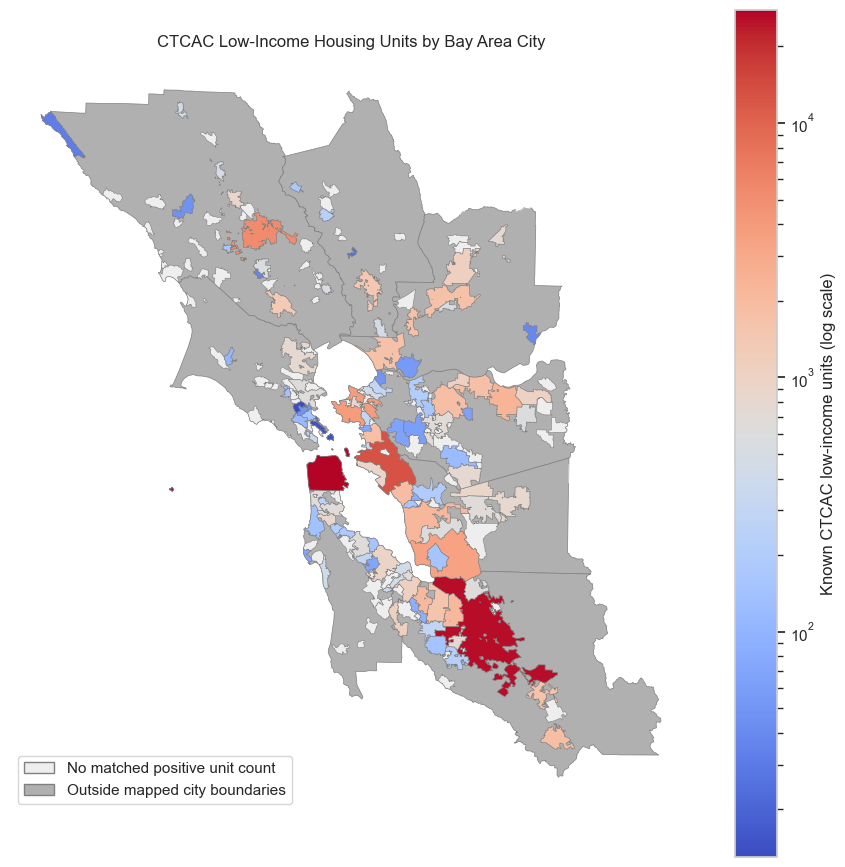

In [16]:
from matplotlib.colors import LogNorm
fig, ax = plt.subplots(figsize=(11, 11))
# Areas outside city boundaries
bay_boundary.plot(ax=ax, color="#b0b0b0", edgecolor="gray", linewidth=0.5)

# Cities with no matched positive unit count
bay_cities.plot(ax=ax, color="#eeeeee", edgecolor="gray", linewidth=0.4)

# Color cities
positive = bay_cities[bay_cities["Low Income Units"] > 0]
if not positive.empty:
    positive.plot(
        column="Low Income Units",
        ax=ax,
        cmap="coolwarm",
        norm=LogNorm(
            vmin=max(1, positive["Low Income Units"].min()),
            vmax=positive["Low Income Units"].max()
        ),
        edgecolor="gray",
        linewidth=0.4,
        legend=True,
        legend_kwds={"label": "Known CTCAC low-income units (log scale)"}
    )

ax.set_title("CTCAC Low-Income Housing Units by Bay Area City")
ax.set_axis_off()
from matplotlib.patches import Patch

legend_items = [
    Patch(facecolor="#eeeeee", edgecolor="gray",
          label="No matched positive unit count"),
    Patch(facecolor="#b0b0b0", edgecolor="gray",
          label="Outside mapped city boundaries")
]

ax.legend(handles=legend_items, loc="lower left")
plt.show()

Number of CTCAC low-income housing units across cities in the San Francisco Bay Area

## Households below HAMFI

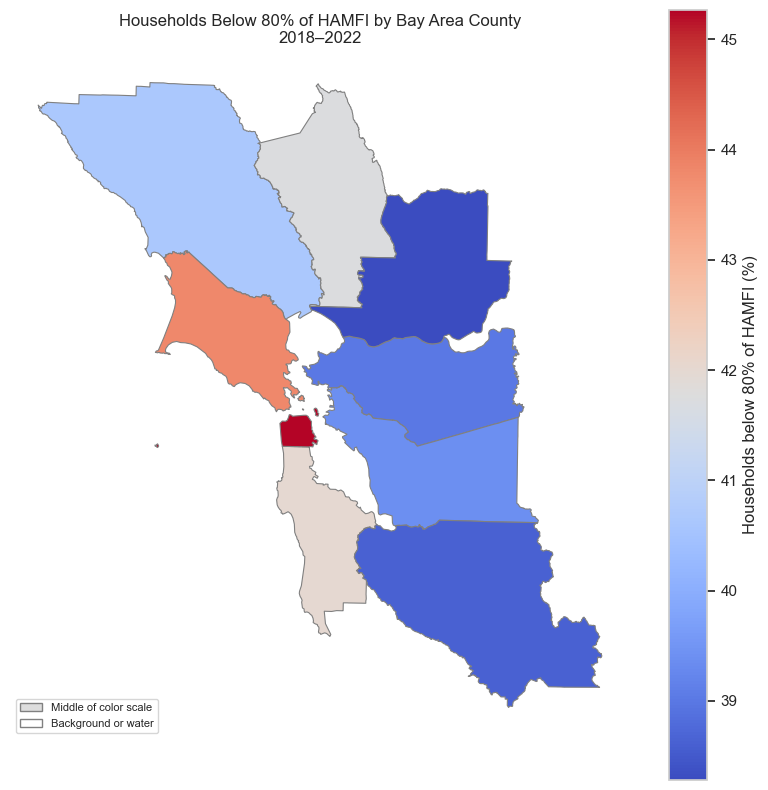

,NAME,Percent below 80%
0,Alameda,39.380697
1,Contra Costa,39.016241
2,Marin,43.804840
3,Napa,41.731004
4,San Francisco,45.266600
5,San Mateo,42.005107
6,Santa Clara,38.613055
7,Solano,38.281124
8,Sonoma,40.634310


In [ ]:
# Draw the map
fig, ax = plt.subplots(figsize=(10, 10))

bay_map.plot(
    column="Percent below 80%",
    cmap="coolwarm",
    edgecolor="gray",
    linewidth=0.8,
    legend=True,
    legend_kwds={"label": "Households below 80% of HAMFI (%)"},
    missing_kwds={"color": "lightgray", "label": "Missing data"},
    ax=ax,
)

ax.set_title("Households Below 80% of HAMFI by Bay Area County\n2018–2022")
ax.set_axis_off()

from matplotlib.patches import Patch

legend_items = [
    Patch(facecolor="#dddddd", edgecolor="gray",
          label="Middle of color scale"),
    Patch(facecolor="white", edgecolor="gray",
          label="Background or water")
]

ax.legend(handles=legend_items, loc="lower left", fontsize=8)
plt.show()

# Show the values for the map
display(
    bay_map[["NAME", "Percent below 80%"]]
    .sort_values("NAME")
    .reset_index(drop=True)
)

12 of 22 epicenters fall inside the nine counties; the rest are in neighboring counties (mostly south, toward Hollister and Monterey Bay).


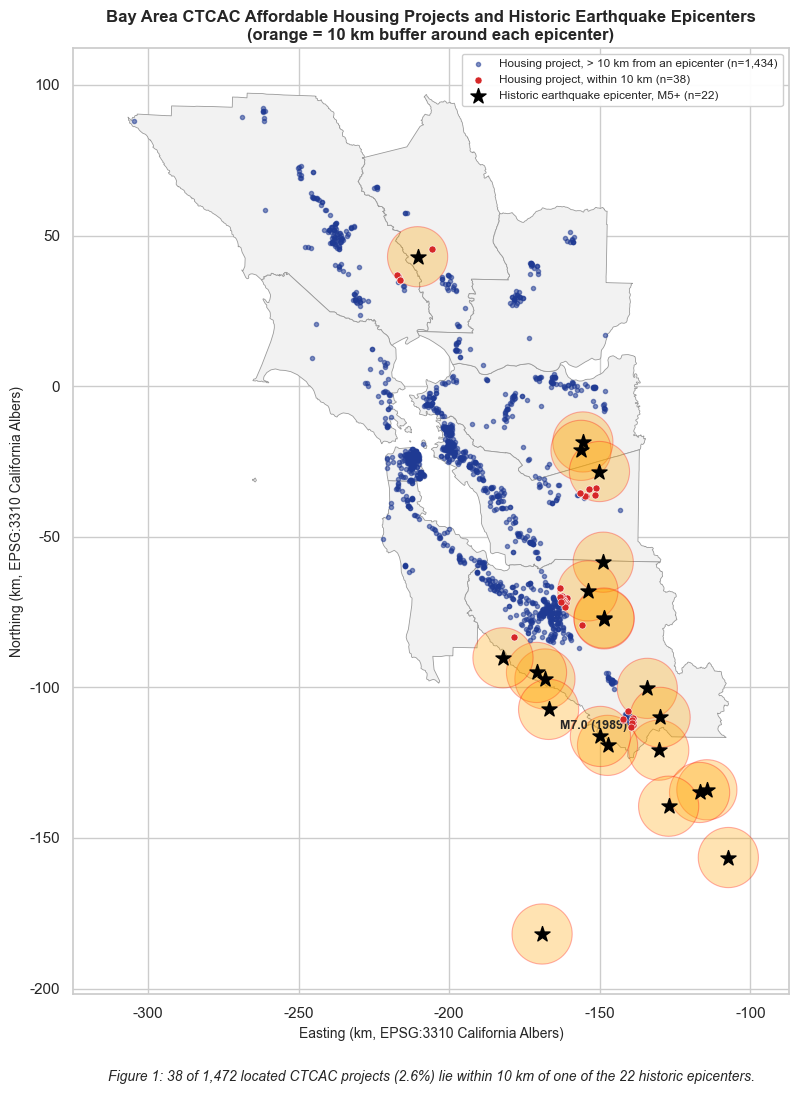

In [17]:
try:
    counties = gpd.read_file("https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_500k.zip")
    counties = counties[(counties["STATEFP"] == "06") & (counties["NAME"].isin(BAY_COUNTIES))].to_crs(PROJ_CRS)
except Exception as e:
    counties = None
    print("County outlines not drawn:", e)

if counties is not None:
    in_bay = gpd.sjoin(gdf_eq, counties[["NAME", "geometry"]], how="inner", predicate="within")
    print(f"{in_bay['eq_no'].nunique()} of {len(gdf_eq)} epicenters fall inside the nine counties; "
          "the rest are in neighboring counties (mostly south, toward Hollister and Monterey Bay).")

near = result[result[f"within_{MAIN_BUFFER_KM}km"]]
far = result[~result[f"within_{MAIN_BUFFER_KM}km"]]
buf_plot = gdf_eq.copy()
buf_plot["geometry"] = buf_plot.geometry.buffer(MAIN_BUFFER_KM * 1000)

fig, ax = plt.subplots(figsize=(10, 11))
if counties is not None:
    counties.plot(ax=ax, color="#f2f2f2", edgecolor="#9a9a9a", linewidth=0.6, zorder=1)
buf_plot.plot(ax=ax, color="orange", alpha=0.30, edgecolor="red", linewidth=0.8, zorder=2)
ax.scatter(far.geometry.x, far.geometry.y, s=9, c="#1f3a93", alpha=0.55, zorder=3,
           label=f"Housing project, > {MAIN_BUFFER_KM} km from an epicenter (n={len(far):,})")
ax.scatter(near.geometry.x, near.geometry.y, s=26, c="#d62728", edgecolor="white", linewidth=0.4,
           zorder=4, label=f"Housing project, within {MAIN_BUFFER_KM} km (n={len(near):,})")
ax.scatter(gdf_eq.geometry.x, gdf_eq.geometry.y, marker="*", s=130, c="black", zorder=5,
           label=f"Historic earthquake epicenter, M{gdf_eq['mag'].min():.0f}+ (n={len(gdf_eq)})")
for _, q in gdf_eq[gdf_eq["mag"] >= 7].iterrows():
    ax.annotate(f"M{q['mag']:.1f} ({q['year']})", (q.geometry.x, q.geometry.y),
                xytext=(8, -14), textcoords="offset points", fontsize=9, fontweight="bold")

xs = pd.concat([result.geometry.x, gdf_eq.geometry.x]); ys = pd.concat([result.geometry.y, gdf_eq.geometry.y])
pad = 20000
ax.set_xlim(xs.min() - pad, xs.max() + pad); ax.set_ylim(ys.min() - pad, ys.max() + pad)
ax.set_aspect("equal")
km = FuncFormatter(lambda v, _: f"{v / 1000:,.0f}")
ax.xaxis.set_major_formatter(km); ax.yaxis.set_major_formatter(km)
ax.set_xlabel("Easting (km, EPSG:3310 California Albers)"); ax.set_ylabel("Northing (km, EPSG:3310 California Albers)")
ax.set_title(f"Bay Area CTCAC Affordable Housing Projects and Historic Earthquake Epicenters\n"
             f"(orange = {MAIN_BUFFER_KM} km buffer around each epicenter)", fontsize=12, fontweight="bold")
ax.legend(loc="upper right", fontsize=8.5, framealpha=0.95)

row = summary[summary["radius_km"] == MAIN_BUFFER_KM].iloc[0]
fig.text(0.5, 0.01,
         f"Figure 1: {row['projects_within']:.0f} of {len(result):,} located CTCAC projects "
         f"({row['pct_projects']:.1f}%) lie within {MAIN_BUFFER_KM} km of one of the {len(gdf_eq)} historic epicenters.",
         ha="center", fontsize=10, style="italic", wrap=True)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(f"{OUT_DIR}/map_housing_earthquakes.png", dpi=300)
plt.show()

# Graphs

## Buffer Radius to Earthquake Epicenters

In [18]:
def style(fig, title, sub, h=520):
    fig.update_layout(template="plotly_white", font=dict(size=14), height=h,
                      title=dict(text=f"<b>{title}</b><br><sup>{sub}</sup>", x=0.02),
                      legend=dict(orientation="h", y=-0.2), hoverlabel=dict(font_size=13),
                      margin=dict(l=60, r=30, t=90, b=60))
    return fig

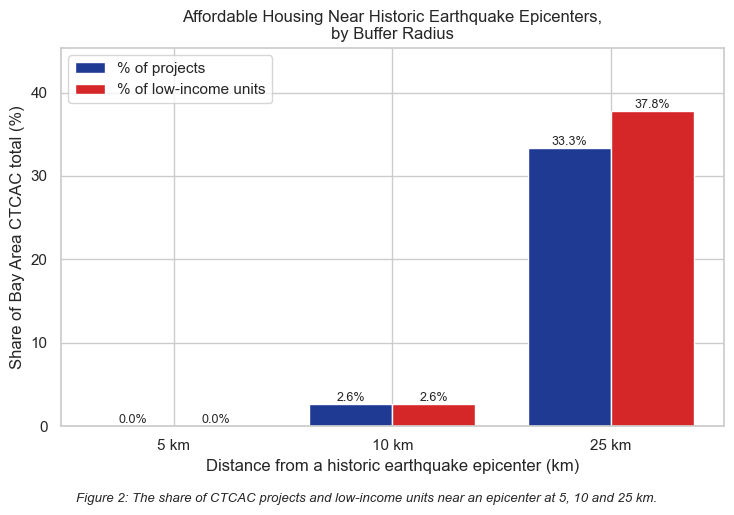

In [19]:
x = np.arange(len(summary)); w = 0.38
fig, ax = plt.subplots(figsize=(7.5, 5))
b1 = ax.bar(x - w / 2, summary["pct_projects"], w, label="% of projects", color="#1f3a93")
b2 = ax.bar(x + w / 2, summary["pct_low_income_units"], w, label="% of low-income units", color="#d62728")
ax.bar_label(b1, fmt="%.1f%%", fontsize=9); ax.bar_label(b2, fmt="%.1f%%", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([f"{r} km" for r in summary["radius_km"]])
ax.set_xlabel("Distance from a historic earthquake epicenter (km)")
ax.set_ylabel("Share of Bay Area CTCAC total (%)")
ax.set_title("Affordable Housing Near Historic Earthquake Epicenters,\nby Buffer Radius")
ax.legend(); ax.set_ylim(0, max(summary["pct_projects"].max(), summary["pct_low_income_units"].max()) * 1.2)
fig.text(0.5, -0.02, "Figure 2: The share of CTCAC projects and low-income units near an epicenter at 5, 10 and 25 km.",
         ha="center", fontsize=9.5, style="italic")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/chart_exposure_by_buffer.png", dpi=300, bbox_inches="tight")
plt.show()

## Distance of Housing to Hazard Zones

There are two lines, and each one covers all 1,472 located housing projects. The blue line measures each project’s distance to the nearest historic earthquake epicenter. The red line measures distance to the nearest Alquist-Priolo (AP) fault zone.

In [20]:
long = result[["Project Name","county","dist_km","dist_ap_km"]].melt(
    id_vars=["Project Name","county"], var_name="measure", value_name="km")
long["measure"] = long["measure"].map({"dist_km":"Nearest historic epicenter",
                                       "dist_ap_km":"Nearest AP fault zone"})
fig = px.ecdf(long, x="km", color="measure", ecdfnorm="percent",
              hover_data=["Project Name","county"], color_discrete_sequence=["#1f3a93","#d62728"])
for k in [1, 5, 10, 25]:
    fig.add_vline(x=k, line_dash="dot", line_color="gray", annotation_text=f"{k} km")
fig.update_xaxes(title="Distance from project (km)", range=[0, 60])
fig.update_yaxes(title="Cumulative % of CTCAC projects", ticksuffix="%")
style(fig, "How close is affordable housing to seismic hazards?",
      "Each line = all located projects, sorted by distance. Higher/left = closer.").show()

## Seismic Hazard Land Share to Low Income
Each bubble is one county. The x-axis is the % of the county’s land inside AP fault zones. The y-axis is the % of households earning below 80% of the area median income

In [21]:
cty = counties[["NAME","geometry"]].copy(); cty["km2"] = cty.area/1e6
ov = gpd.overlay(cty, ap_union, how="intersection"); ov["ap_km2"] = ov.area/1e6
cty = cty.merge(ov[["NAME","ap_km2"]], on="NAME", how="left").fillna({"ap_km2":0})
cty["pct_ap"] = 100*cty["ap_km2"]/cty["km2"]
bay_income["renter_pct"] = 100*bay_income["T8_est68"]/bay_income["T8_est1"]
cty = cty.merge(bay_income[["county","Percent below 80%","renter_pct"]], left_on="NAME", right_on="county")

r = np.corrcoef(cty["pct_ap"], cty["Percent below 80%"])[0, 1]
fig = px.scatter(cty, x="pct_ap", y="Percent below 80%", size="renter_pct", color="renter_pct",
                 text="NAME", size_max=45, color_continuous_scale="Viridis", hover_name="NAME",
                 hover_data={"NAME":False, "pct_ap":":.2f", "Percent below 80%":":.1f",
                             "renter_pct":":.1f", "ap_km2":":.1f"},
                 labels={"pct_ap":"Land in AP fault zones (%)", "Percent below 80%":"Households below 80% HAMFI (%)",
                         "renter_pct":"Renters (%)", "ap_km2":"AP zone area (km²)"})
fig.update_traces(textposition="top center", marker=dict(line=dict(width=1, color="black")))
style(fig, "Seismic hazard land share vs. low-income share, by county",
      f"Bubble size & color = renter share · Pearson r = {r:.2f} (n = 9 counties)").show()

## Afford Housing Exposure to Mapped Fault Zones
For each county, the % of its affordable (CTCAC low-income) units within 1 km of an AP fault zone.

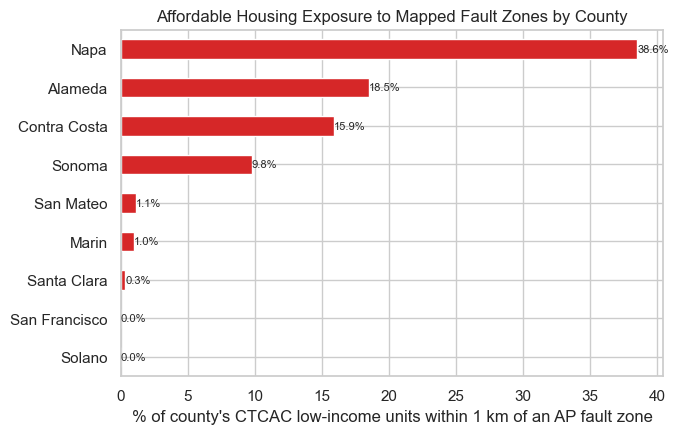

In [22]:
c = (result.groupby("county")
     .apply(lambda d: 100*d.loc[d["near_ap"],"Low Income Units"].sum()/d["Low Income Units"].sum())
     .sort_values())
ax = c.plot.barh(figsize=(7,4.5), color="#d62728")
ax.bar_label(ax.containers[0], fmt="%.1f%%", fontsize=8)
ax.set(xlabel="% of county's CTCAC low-income units within 1 km of an AP fault zone", ylabel="",
       title="Affordable Housing Exposure to Mapped Fault Zones by County"); plt.show()

## Renters vs Owners
For each county, one dot gives the % of owners below 80% HAMFI and the other gives the % of renters. The gray bar connects the two.

In [23]:
t = bay_income.set_index("county")
tenure = pd.DataFrame({
    "Owners":  100*(t["T8_est3"]+t["T8_est16"]+t["T8_est29"])/t["T8_est2"],
    "Renters": 100*(t["T8_est69"]+t["T8_est82"]+t["T8_est95"])/t["T8_est68"]}).sort_values("Renters")
fig = go.Figure()
for c in tenure.index:
    fig.add_trace(go.Scatter(x=tenure.loc[c, ["Owners","Renters"]], y=[c, c], mode="lines",
                             line=dict(color="lightgray", width=4), showlegend=False, hoverinfo="skip"))
for col, colr in [("Owners","#1f3a93"), ("Renters","#f28e2b")]:
    fig.add_trace(go.Scatter(x=tenure[col], y=tenure.index, mode="markers", name=col,
                             marker=dict(size=14, color=colr, line=dict(width=1, color="white")),
                             hovertemplate="%{y}<br>"+col+": %{x:.1f}%<extra></extra>"))
fig.update_xaxes(title="Households below 80% HAMFI (%)", ticksuffix="%", range=[0, 80])
style(fig, "Low-income share: renters vs. owners, by county",
      "Gap between dots = renter–owner difference · CHAS 2018–2022").show()

## Historic M5+ Earthquakes near Fault zones
Each dot is one of the 22 historic M5+ earthquakes. The x-axis is its distance to the nearest AP fault zone, and the y-axis is its magnitude. Color shows the year

In [24]:
eq = gpd.sjoin_nearest(gdf_eq[["eq_no","date","mag","depth_km","year","geometry"]],
                       faults[["zone_name","geometry"]], distance_col="d_m")
eq = eq[~eq.index.duplicated()].copy()
eq["d_km"] = eq["d_m"]/1000
eq["date_str"] = pd.to_datetime(eq["date"]).dt.strftime("%b %d, %Y")
fig = px.scatter(eq, x="d_km", y="mag", size="mag", size_max=22, color="year",
                 color_continuous_scale="Plasma", hover_name="zone_name",
                 hover_data={"date_str":True, "mag":":.1f", "depth_km":":.1f", "d_km":":.1f", "year":False},
                 labels={"d_km":"Distance to nearest AP fault zone (km)", "mag":"Magnitude",
                         "date_str":"Date", "depth_km":"Depth (km)", "year":"Year"})
fig.add_vrect(x0=0, x1=5, fillcolor="green", opacity=0.08, line_width=0,
              annotation_text="within 5 km", annotation_position="top left")
fig.update_traces(marker=dict(line=dict(width=1, color="black")))
style(fig, "Do historic M5+ earthquakes occur near mapped fault zones?",
      f"{(eq['d_km']<=5).sum()} of {len(eq)} epicenters fall within 5 km of an AP zone · hover for details").show()

## CTAC Units Placement to Fault Zones
Affordable units placed in service each year. The red part of each bar is units within 1 km of a fault zone, and the gray part is everything else. A dashed line marks the 1989 Loma Prieta earthquake.

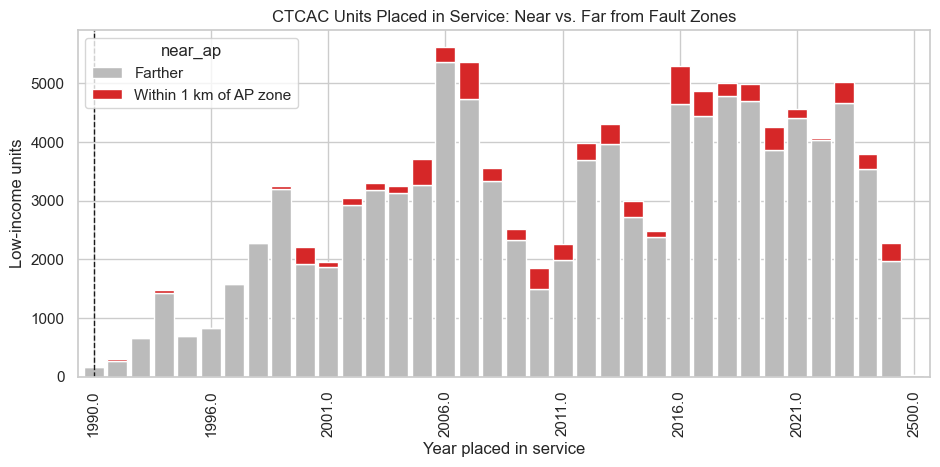

In [25]:
yr = (result.dropna(subset=["year_placed"])
      .pivot_table(index="year_placed", columns="near_ap", values="Low Income Units", aggfunc="sum", fill_value=0)
      .rename(columns={True:"Within 1 km of AP zone", False:"Farther"}))
ax = yr.plot.bar(stacked=True, figsize=(11,4.5), width=0.85, color=["#bbbbbb","#d62728"])
ax.axvline(list(yr.index).index(1989) if 1989 in yr.index else 0, color="k", ls="--", lw=1)
ax.set(xlabel="Year placed in service", ylabel="Low-income units", title="CTCAC Units Placed in Service: Near vs. Far from Fault Zones")
ax.set_xticks(ax.get_xticks()[::5]); plt.show()